# PBL JS15 - Pipeline ML dan Deployment Detektor URL Berbahaya

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js15-pipeline-machine-learning-and-deployment)

Notebook ini menerapkan langkah-langkah jobsheet JS15 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS15 | Penerapan pada URL |
| --- | --- |
| Praktikum 1 - load, preprocessing, ekstraksi fitur, scaler, split, NN, evaluasi, simpan `.h5` + `.pkl` | URL → 28 fitur leksikal → StandardScaler → NN 128-64-softmax |
| Praktikum 2 - Flask `app.py`, `requirements.txt`, `Dockerfile`, Hugging Face Space | Folder [`url-project/`](url-project/) dengan input teks URL |
| Tugas - deploy model sendiri | Model PBL deteksi URL berbahaya |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Langkah 1-3 - Load dataset, preprocessing, dan label encoding

In [2]:
import pickle, shutil, re, json
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
tf.keras.utils.set_random_seed(42)
df = pbl_url.load_urls()
CLASS_NAMES = sorted(pbl_url.CLASSES)
y = df['type'].map({c: i for i, c in enumerate(CLASS_NAMES)}).to_numpy()
print(df.shape, dict(enumerate(CLASS_NAMES)))

(783705, 2) {0: 'Exploit', 1: 'benign', 2: 'defacement', 3: 'legitimate', 4: 'malware', 5: 'phishing', 6: 'spam'}


## Langkah 4 - Ekstraksi fitur (pengganti HOG): 28 fitur leksikal + log1p

In [3]:
t0 = time.perf_counter()
X = np.log1p(pbl_url.lexical_features(df['url']).clip(lower=0)).to_numpy(np.float32)
print(X.shape, f'{time.perf_counter() - t0:.1f} s')

(783705, 28) 19.1 s


## Langkah 5-7 - Split train/test, normalisasi (fit pada train), split validasi

In [4]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)
X_train, X_val, y_train, y_val = train_test_split(X_train_scaled, y_train, test_size=0.2, stratify=y_train, random_state=42)

## Langkah 8-9 - Arsitektur dan training model

In [5]:
model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(CLASS_NAMES), activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()
history = model.fit(X_train, y_train, epochs=20, batch_size=256, validation_data=(X_val, y_val), verbose=2,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,423 (48.53 KB)

 Trainable params: 12,423 (48.53 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (35 outputs left out)

Epoch 19/20


1960/1960 - 1s - 426us/step - accuracy: 0.8152 - loss: 0.4528 - val_accuracy: 0.8117 - val_loss: 0.4649


Epoch 20/20


1960/1960 - 1s - 426us/step - accuracy: 0.8157 - loss: 0.4515 - val_accuracy: 0.8122 - val_loss: 0.4644


## Langkah 10-11 - Evaluasi, classification report, confusion matrix

Akurasi Test: 0.812 | macro-F1: 0.6373
              precision    recall  f1-score   support

     Exploit     0.8889    0.4898    0.6316        49
      benign     0.8292    0.8721    0.8501     85286
  defacement     0.8741    0.8072    0.8393     19053
  legitimate     0.4762    0.0258    0.0490      1162
     malware     0.9378    0.8334    0.8825      4718
    phishing     0.7418    0.7263    0.7340     45923
        spam     0.8900    0.3236    0.4747       550

    accuracy                         0.8120    156741
   macro avg     0.8054    0.5826    0.6373    156741
weighted avg     0.8099    0.8120    0.8084    156741



,Exploit,benign,defacement,legitimate,malware,phishing,spam
Exploit,24,0,0,0,18,7,0
benign,0,74381,1398,20,39,9440,8
defacement,0,2377,15380,0,2,1294,0
legitimate,0,820,11,30,1,300,0
malware,1,257,55,0,3932,473,0
phishing,2,11596,745,13,201,33352,14
spam,0,273,6,0,0,93,178


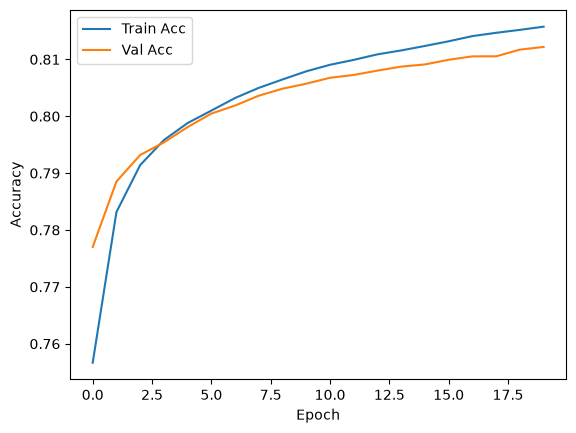

In [6]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0, batch_size=4096)
y_pred = model.predict(X_test_scaled, verbose=0, batch_size=4096).argmax(1)
print('Akurasi Test:', round(test_acc, 4), '| macro-F1:', round(f1_score(y_test, y_pred, average='macro'), 4))
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, y_pred), index=CLASS_NAMES, columns=CLASS_NAMES))
plt.plot(history.history['accuracy'], label='Train Acc'); plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

## Langkah 12 - Simpan model, scaler, dan kode fitur ke folder deploy

In [7]:
out = Path('url-project'); out.mkdir(exist_ok=True)
model.save(out / 'url_model.h5', include_optimizer=False)
with open(out / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
(out / 'labels.json').write_text(json.dumps(CLASS_NAMES))
shutil.copy('../pbl_url.py', out / 'pbl_url.py')   # definisi fitur yang SAMA dengan training (hindari training-serving skew)
for f in sorted(out.iterdir()):
    if f.is_file(): print(f'{f.name:18s} {f.stat().st_size / 1e3:8.1f} KB')

Dockerfile              0.7 KB
README.md               0.7 KB
app.py                  2.7 KB
labels.json             0.1 KB
pbl_url.py              4.2 KB
requirements.txt        0.1 KB
scaler.pkl              1.1 KB
url_model.h5           70.2 KB


## Praktikum 2 / Tugas - `app.py`, `requirements.txt`, `Dockerfile`

In [8]:
for name in ['app.py', 'requirements.txt', 'Dockerfile']:
    print(f'===== {name} ====='); print((out / name).read_text())

===== app.py =====
import json
import pickle

import numpy as np
import tensorflow as tf
from flask import Flask, request, render_template_string

from pbl_url import lexical_features, normalize_url

app = Flask(__name__)

# Load Model, Scaler & Label
MODEL_PATH = 'url_model.h5'
SCALER_PATH = 'scaler.pkl'
LABELS_PATH = 'labels.json'
BENIGN = {'benign', 'legitimate'}

try:
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    with open(SCALER_PATH, 'rb') as f:
        scaler = pickle.load(f)
    with open(LABELS_PATH) as f:
        labels = json.load(f)
    print("✅ System Loaded Successfully")
except Exception as e:
    print(f"❌ Error loading system: {e}")

def preprocess_url(url):
    # Preprocessing harus sama persis dengan training: normalisasi -> 28 fitur leksikal -> log1p -> scaler
    feats = lexical_features([normalize_url(url)]).clip(lower=0)
    return scaler.transform(np.log1p(feats.to_numpy(np.float32)))

FORM = '''
<div style="max-width:640px; margin:auto; 

## Uji aplikasi Flask secara lokal sebelum upload

In [9]:
import os, importlib
os.chdir('url-project'); sys.path.insert(0, os.getcwd())
sys.modules.pop('pbl_url', None)
app_module = importlib.import_module('app'); client = app_module.app.test_client()
print('GET / ->', client.get('/').status_code)
idx = np.random.RandomState(0).choice(len(X_test_raw), 2000, replace=False)
_, url_test = train_test_split(df['url'].to_numpy(), test_size=0.2, stratify=y, random_state=42)
api = []
for i in idx:
    text = client.post('/predict', data={'url': url_test[i]}).get_data(as_text=True)
    api.append(re.search(r'Hasil: <b>([A-Za-z]+)</b>', text).group(1))
agree = np.mean(np.array(api) == np.array(CLASS_NAMES)[y_pred[idx]])
print(f'Kesesuaian prediksi endpoint vs notebook pada 2.000 URL test: {agree:.4f}')
for u in ['paypal-account-verify.secure-login.xyz/webscr?cmd=update', '185.244.25.10/bins/mirai.arm7', 'google.com']:
    print(u, '->', re.sub('<[^>]+>', ' ', client.post('/predict', data={'url': u}).get_data(as_text=True)).split('Hasil:')[1].split('Kembali')[0].strip())
print('Input kosong ->', client.post('/predict', data={'url': '  '}).status_code)
os.chdir('..')

✅ System Loaded Successfully
GET / -> 200


Kesesuaian prediksi endpoint vs notebook pada 2.000 URL test: 1.0000
paypal-account-verify.secure-login.xyz/webscr?cmd=update -> phishing  (berbahaya) 
     paypal-account-verify.secure-login.xyz/webscr?cmd=update 
       phishing  0.979    benign  0.021    malware  0.000    legitimate  0.000    defacement  0.000    spam  0.000    Exploit  0.000
185.244.25.10/bins/mirai.arm7 -> malware  (berbahaya) 
     185.244.25.10/bins/mirai.arm7 
       malware  0.973    phishing  0.017    Exploit  0.009    benign  0.000    defacement  0.000    legitimate  0.000    spam  0.000
google.com -> benign  (aman) 
     google.com 
       benign  0.551    phishing  0.225    legitimate  0.199    spam  0.013    malware  0.012    defacement  0.000    Exploit  0.000
Input kosong -> 400


## Deploy ke Hugging Face Spaces

    ```bash
    git lfs install
    git clone https://huggingface.co/spaces/USERNAME_ANDA/url-detector-244107020049    # Space baru, SDK Docker
    cp JS15/url-project/{app.py,pbl_url.py,labels.json,Dockerfile,requirements.txt,url_model.h5,scaler.pkl,README.md} url-detector-244107020049/
    cd url-detector-244107020049 && git add . && git commit -m "Deploy detektor URL" && git push
    ```

    ## Analisis


**Model.** Dengan pipeline jobsheet (fitur → StandardScaler → NN 128-64-softmax, 20 epoch), accuracy test 0,812 dan macro-F1 0,637. EarlyStopping tidak berhenti lebih awal karena loss validasi masih turun pelan. Confusion matrix menunjukkan kesalahan terbesar ada pada pasangan **benign ↔ phishing**: 9.440 benign diprediksi phishing, dan 11.596 phishing diprediksi benign. Legitimate hampir selalu diprediksi benign (820 dari 1.162).

**Artefak deploy** sangat kecil: `url_model.h5` 70 KB dan `scaler.pkl` 1 KB. Ukuran ini jauh di bawah batas 10 MB Hugging Face tanpa Git LFS, berbeda dengan model Day vs Night (18 MB) yang memakai 34.596 fitur HOG.

**Konsistensi training-serving.**
* `app.py` memakai **berkas `pbl_url.py` yang sama** dengan training (disalin otomatis di Langkah 12), sehingga definisi 28 fitur tidak dapat berbeda antara notebook dan server. Sculley dkk. (2015) menyebut perbedaan seperti itu sebagai sumber utama *training-serving skew*.
* Pada 2.000 URL test, prediksi lewat endpoint `/predict` **100% identik** dengan prediksi notebook.
* `app.py` menambahkan `normalize_url`, karena dataset tidak memuat `http(s)://` dan `www.` sedangkan pengguna biasanya mengetiknya. Tanpa normalisasi, `https://www.` akan menambah 12 karakter dan mengubah `url_len`, `n_slashes`, dan fitur lainnya. Input kosong ditolak dengan HTTP 400, dan input lebih dari 2.048 karakter juga ditolak.

**Uji perilaku.**
* `paypal-account-verify.secure-login.xyz/webscr?cmd=update` → phishing (0,979).
* `185.244.25.10/bins/mirai.arm7` → malware (0,973).
* `google.com` → benign (0,551).
* Pada uji live lewat server (`curl`), `https://www.secure-paypal-login.example.tk/signin/verify.php` → **benign 0,505 vs phishing 0,479**. URL phishing yang dirancang mirip URL normal masih bisa lolos.

Fitur leksikal tidak menangkap isi token (merek `paypal` di subdomain), padahal model n-gram karakter (PBL JS11/JS14) jauh lebih kuat untuk kasus ini.

**Catatan untuk produksi.**
* **Model:** untuk versi berikutnya, deploy model CNN karakter atau TF-IDF + LinearSVC, yang memiliki macro-F1 lebih tinggi. Konsekuensinya, artefak preprocessing yang disimpan berupa vektorizer/kamus karakter, bukan scaler.
* **Evaluasi:** batas keputusan dipilih pada FPR rendah, dan model dievaluasi pada data dari periode waktu yang lebih baru untuk menguji *concept drift* (Arp dkk., 2022).
* **Pemantauan:** pantau distribusi input setelah deploy. Paleyes dkk. (2022) mencatat bahwa pemantauan pascadeploy sering diabaikan dalam kasus nyata.

## Rujukan

1. Sculley, D., Holt, G., Golovin, D., Davydov, E., Phillips, T., Ebner, D., Chaudhary, V., Young, M., Crespo, J.-F., & Dennison, D. (2015). Hidden technical debt in machine learning systems. *Advances in Neural Information Processing Systems 28*, 2503-2511.
2. Paleyes, A., Urma, R.-G., & Lawrence, N. D. (2022). Challenges in deploying machine learning: A survey of case studies. *ACM Computing Surveys*, 55(6), Article 114. https://doi.org/10.1145/3533378
3. Arp, D., Quiring, E., Pendlebury, F., Warnecke, A., Pierazzi, F., Wressnegger, C., Cavallaro, L., & Rieck, K. (2022). Dos and don'ts of machine learning in computer security. *31st USENIX Security Symposium*, 3971-3988.
4. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153
5. Mamun, M. S. I., Rathore, M. A., Lashkari, A. H., Stakhanova, N., & Ghorbani, A. A. (2016). Detecting malicious URLs using lexical analysis. *Network and System Security (NSS 2016)*, LNCS 9955, 467-482. https://doi.org/10.1007/978-3-319-46298-1_30
6. Sahoo, D., Liu, C., & Hoi, S. C. H. (2017). Malicious URL detection using machine learning: A survey. *arXiv:1701.07179*. https://arxiv.org/abs/1701.07179